# Few-Shot Learning — Cross-Split Comparison: B15/N5 vs B10/N10

Compares all FSL methods across both dataset splits and both backbones.

Key questions answered:
- Does DeiT-S backbone consistently outperform ResNet-50?
- Does FCE improve MatchingNet?
- How much does reducing base classes (15→10) hurt performance?
- Does TTA help?
- Which novel classes are hardest across splits?

In [1]:

%matplotlib inline
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=120; plt.rcParams['savefig.dpi']=150
plt.rcParams['figure.facecolor']='white'; plt.rcParams['axes.facecolor']='white'

NB_DIR=os.getcwd()
ROOT=os.path.normpath(os.path.join(NB_DIR,'..'))
RES=os.path.join(ROOT,'results')
ANALYSIS=os.path.join(RES,'analysis')
os.makedirs(ANALYSIS,exist_ok=True)

def load(rel):
    p=os.path.join(RES,rel)
    if os.path.exists(p):
        with open(p) as f: return json.load(f)
    return None

SHOTS=[1,3,5]

# B15/N5
B15={
    'ncc_euc'    :{s:load(f'birds20/baseline/resnet50/base15/novel_ncc/{s}shot_euclidean/summary.json') for s in SHOTS},
    'ncc_man'    :{s:load(f'birds20/baseline/resnet50/base15/novel_ncc/{s}shot_manhattan/summary.json') for s in SHOTS},
    'vit_ncc_euc':{s:load(f'birds20/vit/baseline/base15/novel_ncc/{s}shot_euclidean/summary.json') for s in SHOTS},
    'vit_ncc_man':{s:load(f'birds20/vit/baseline/base15/novel_ncc/{s}shot_manhattan/summary.json') for s in SHOTS},
    'proto_euc'  :{s:load(f'birds20/proto_net/base15_novel5/{s}shot_euclidean/summary.json') for s in SHOTS},
    'proto_man'  :{s:load(f'birds20/proto_net/base15_novel5/{s}shot_manhattan/summary.json') for s in SHOTS},
    'vit_proto_euc':{s:load(f'birds20/vit/proto_net/base15_novel5/{s}shot_euclidean/summary.json') for s in SHOTS},
    'vit_proto_man':{s:load(f'birds20/vit/proto_net/base15_novel5/{s}shot_manhattan/summary.json') for s in SHOTS},
    'match'      :{s:load(f'birds20/matching_net/base15_novel5/{s}shot/summary.json') for s in SHOTS},
    'match_fce'  :{s:load(f'birds20/matching_net_fce/base15_novel5/{s}shot/summary.json') for s in SHOTS},
    'rel'        :{s:load(f'birds20/relation_net/base15_novel5/{s}shot/summary.json') for s in SHOTS},
    'proto_tta8' :{5:load(f'birds20/proto_net/base15_novel5/5shot_euclidean_tta8/summary.json')},
}

# B10/N10
B10={
    'ncc_euc'    :{s:load(f'birds20/baseline/resnet50/base10/novel_ncc/{s}shot_euclidean/summary.json') for s in SHOTS},
    'ncc_man'    :{s:load(f'birds20/baseline/resnet50/base10/novel_ncc/{s}shot_manhattan/summary.json') for s in SHOTS},
    'vit_ncc_euc':{s:load(f'birds20/vit/baseline/base10/novel_ncc/{s}shot_euclidean/summary.json') for s in SHOTS},
    'vit_ncc_man':{s:load(f'birds20/vit/baseline/base10/novel_ncc/{s}shot_manhattan/summary.json') for s in SHOTS},
    'proto_euc'  :{s:load(f'birds20/proto_net/base10_novel10/{s}shot_euclidean/summary.json') for s in SHOTS},
    'proto_man'  :{s:load(f'birds20/proto_net/base10_novel10/{s}shot_manhattan/summary.json') for s in SHOTS},
    'vit_proto_euc':{s:load(f'birds20/vit/proto_net/base10_novel10/{s}shot_euclidean/summary.json') for s in SHOTS},
    'vit_proto_man':{s:load(f'birds20/vit/proto_net/base10_novel10/{s}shot_manhattan/summary.json') for s in SHOTS},
    'match'      :{s:load(f'birds20/matching_net/base10_novel10/{s}shot/summary.json') for s in SHOTS},
    'match_fce'  :{s:load(f'birds20/matching_net_fce/base10_novel10/{s}shot/summary.json') for s in SHOTS},
    'rel'        :{s:load(f'birds20/relation_net/base10_novel10/{s}shot/summary.json') for s in SHOTS},
    'proto_tta8' :{5:load(f'birds20/proto_net/base10_novel10/5shot_euclidean_tta8/summary.json')},
}

def fsl_acc(d): return float(d['mean_accuracy_pct']) if d else float('nan')
def fsl_ci(d):  return float(d['ci95_pct'])          if d else 0.0

METHOD_MAP=[
    ('ncc_euc',    'NCC (Euc)',         '#fd8d3c','o','--'),
    ('ncc_man',    'NCC (Man)',         '#d94801','s',':'),
    ('vit_ncc_euc','NCC/DeiT-S (Euc)', '#9467bd','o','--'),
    ('vit_ncc_man','NCC/DeiT-S (Man)', '#c5b0d5','s',':'),
    ('proto_euc',  'Proto (Euc)',       '#1f77b4','o','-'),
    ('proto_man',  'Proto (Man)',       '#aec7e8','s','-.'),
    ('vit_proto_euc','Proto/DeiT-S (Euc)','#17becf','o','-'),
    ('vit_proto_man','Proto/DeiT-S (Man)','#9edae5','s','-.'),
    ('match',      'MatchingNet',       '#2ca02c','^','-'),
    ('match_fce',  'MatchingNet+FCE',   '#98df8a','^','--'),
    ('rel',        'RelationNet',       '#d62728','D','--'),
]
print('Setup complete.')


Setup complete.


---
## 1. K-Shot Trend: B15/N5 vs B10/N10 (per method)

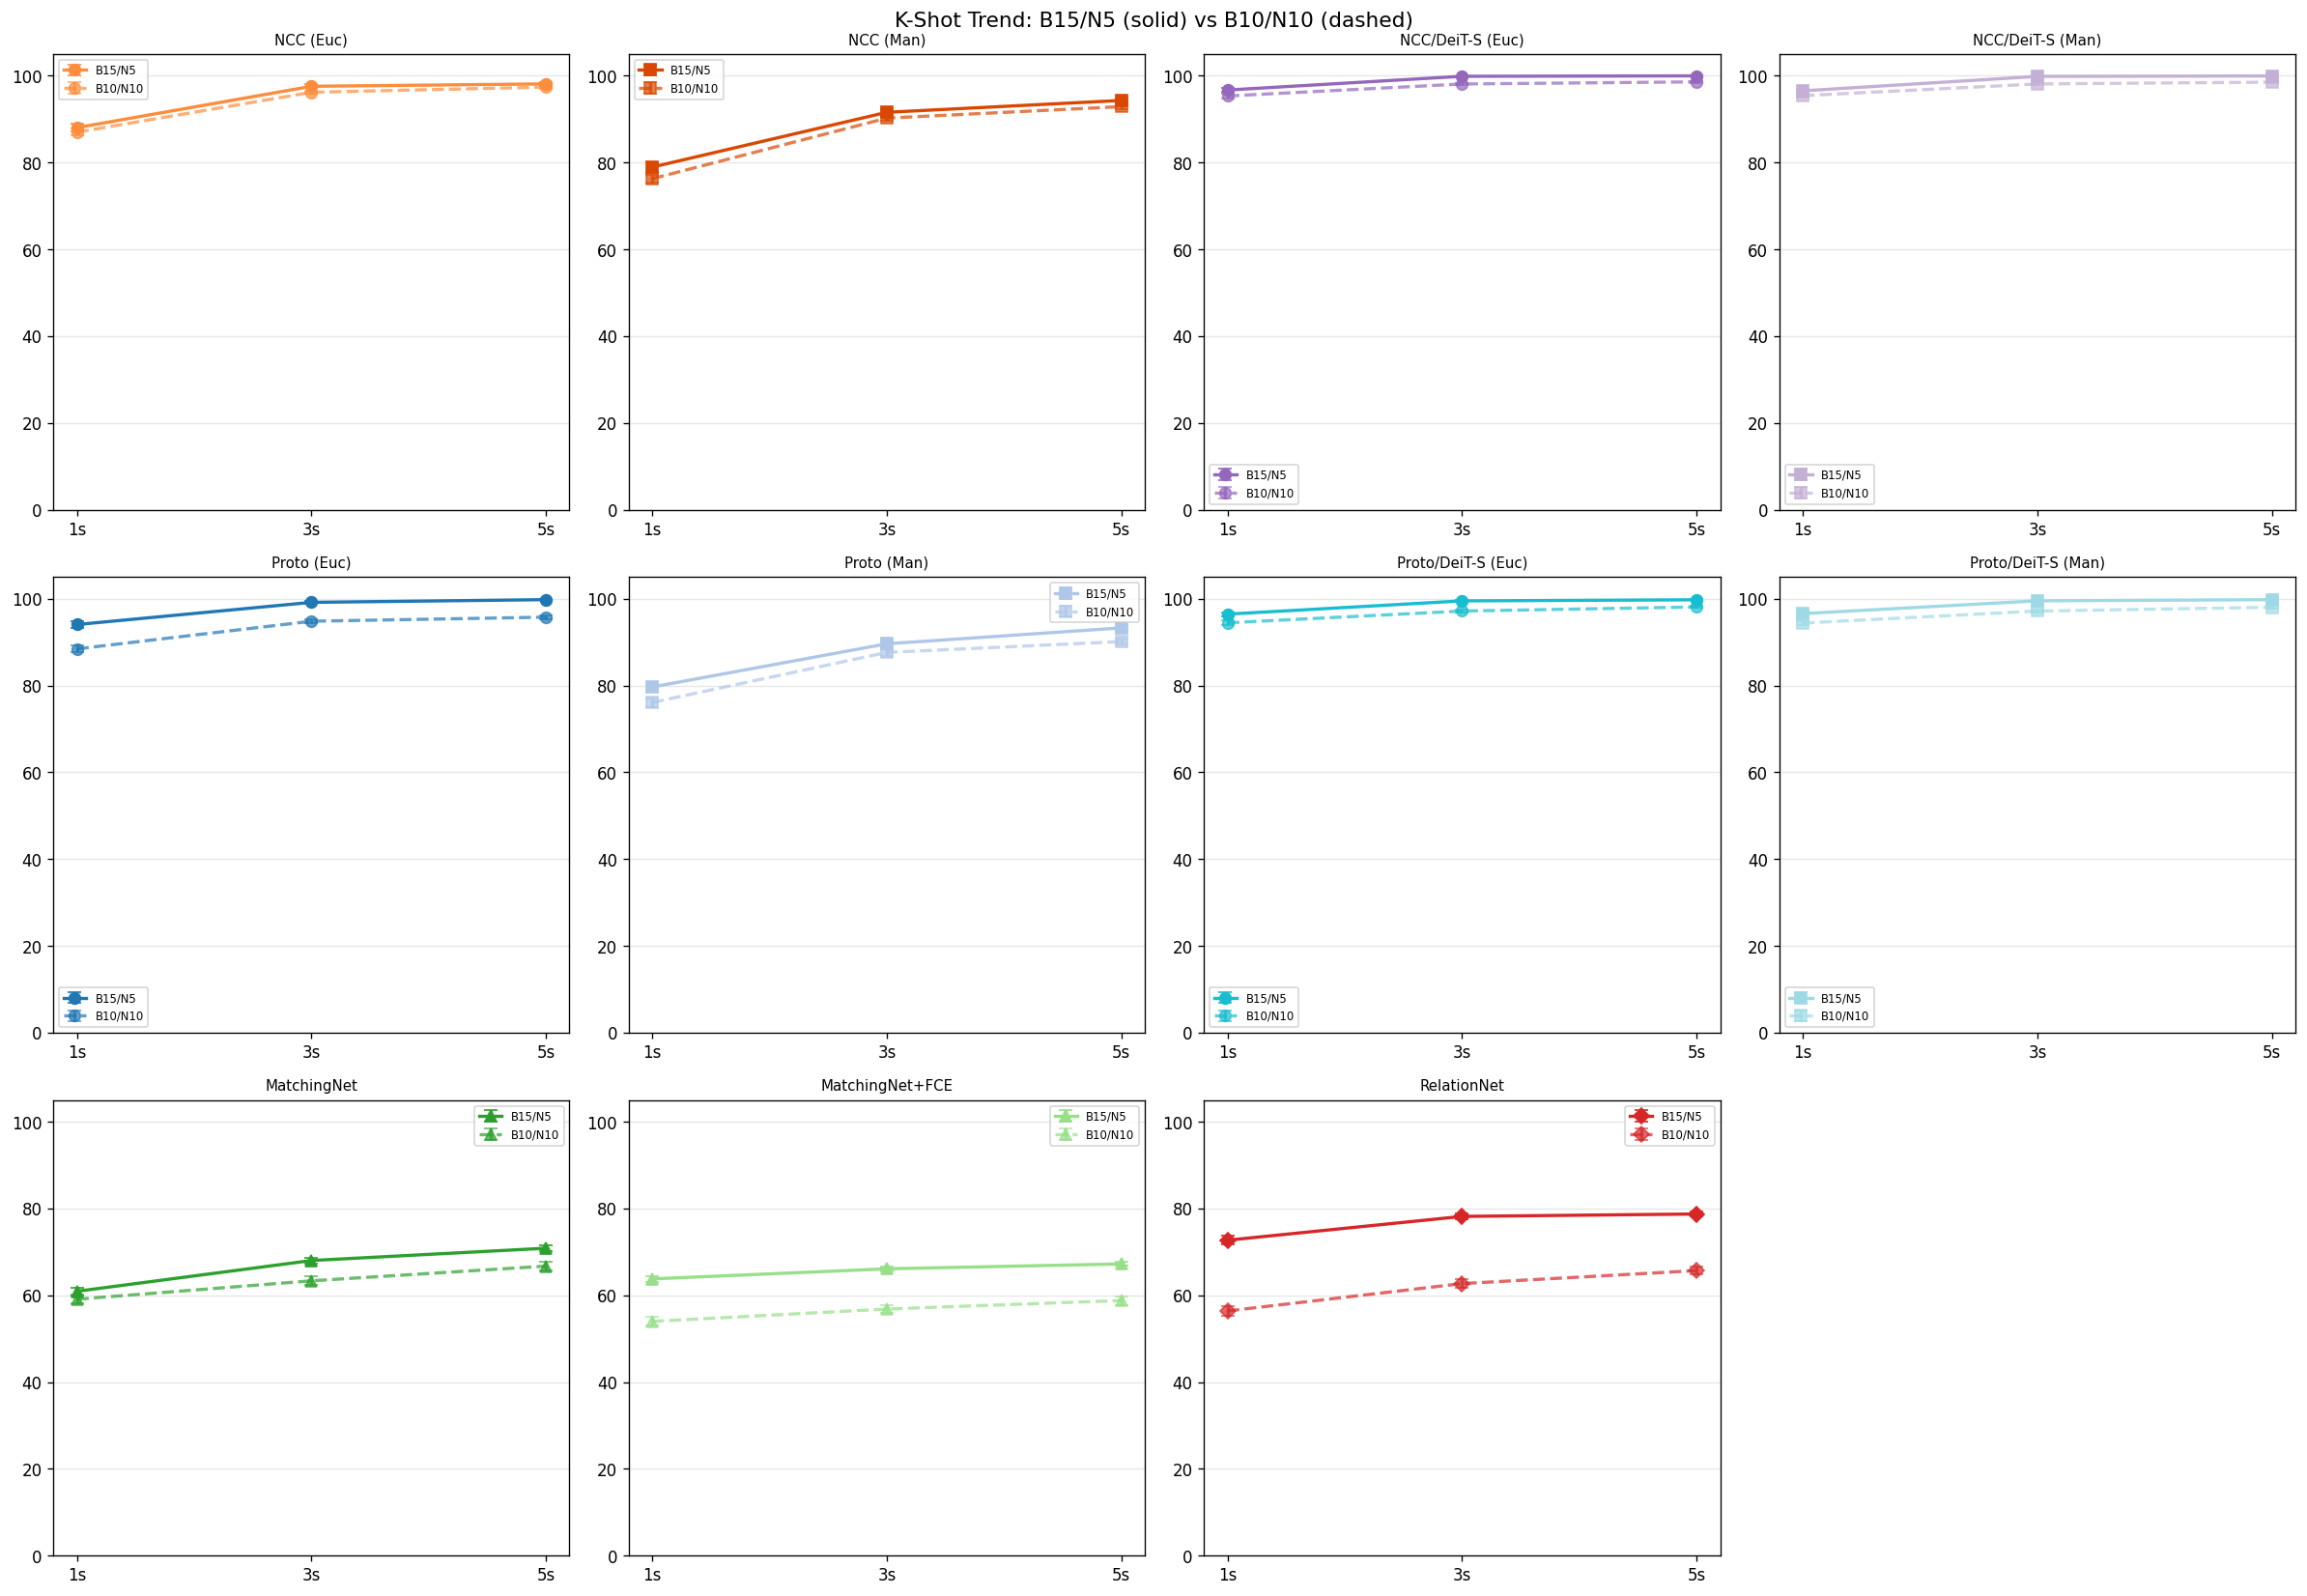

In [2]:

# K-shot trend: B15 vs B10 for each method
fig,axes=plt.subplots(3,4,figsize=(20,14))
axes=axes.flatten()
for ax_i,(mkey,mlabel,color,marker,ls) in enumerate(METHOD_MAP):
    if ax_i>=len(axes): break
    ax=axes[ax_i]
    b15_a=[fsl_acc(B15[mkey].get(s)) for s in SHOTS]
    b10_a=[fsl_acc(B10[mkey].get(s)) for s in SHOTS]
    b15_c=[fsl_ci(B15[mkey].get(s)) for s in SHOTS]
    b10_c=[fsl_ci(B10[mkey].get(s)) for s in SHOTS]
    ax.errorbar(SHOTS,b15_a,yerr=b15_c,label='B15/N5',color=color,marker=marker,linestyle='-',linewidth=2,markersize=7,capsize=4)
    ax.errorbar(SHOTS,b10_a,yerr=b10_c,label='B10/N10',color=color,marker=marker,linestyle='--',linewidth=2,markersize=7,capsize=4,alpha=0.7)
    ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}s' for k in SHOTS])
    ax.set_ylim(0,105); ax.set_title(mlabel,fontsize=9); ax.legend(fontsize=7); ax.grid(axis='y',alpha=0.3)
for ax in axes[len(METHOD_MAP):]: ax.set_visible(False)
fig.suptitle('K-Shot Trend: B15/N5 (solid) vs B10/N10 (dashed)',fontsize=13)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/comparison_kshot_b15_vs_b10.png',dpi=150); plt.show()


---
## 2. Accuracy Delta: B10/N10 − B15/N5

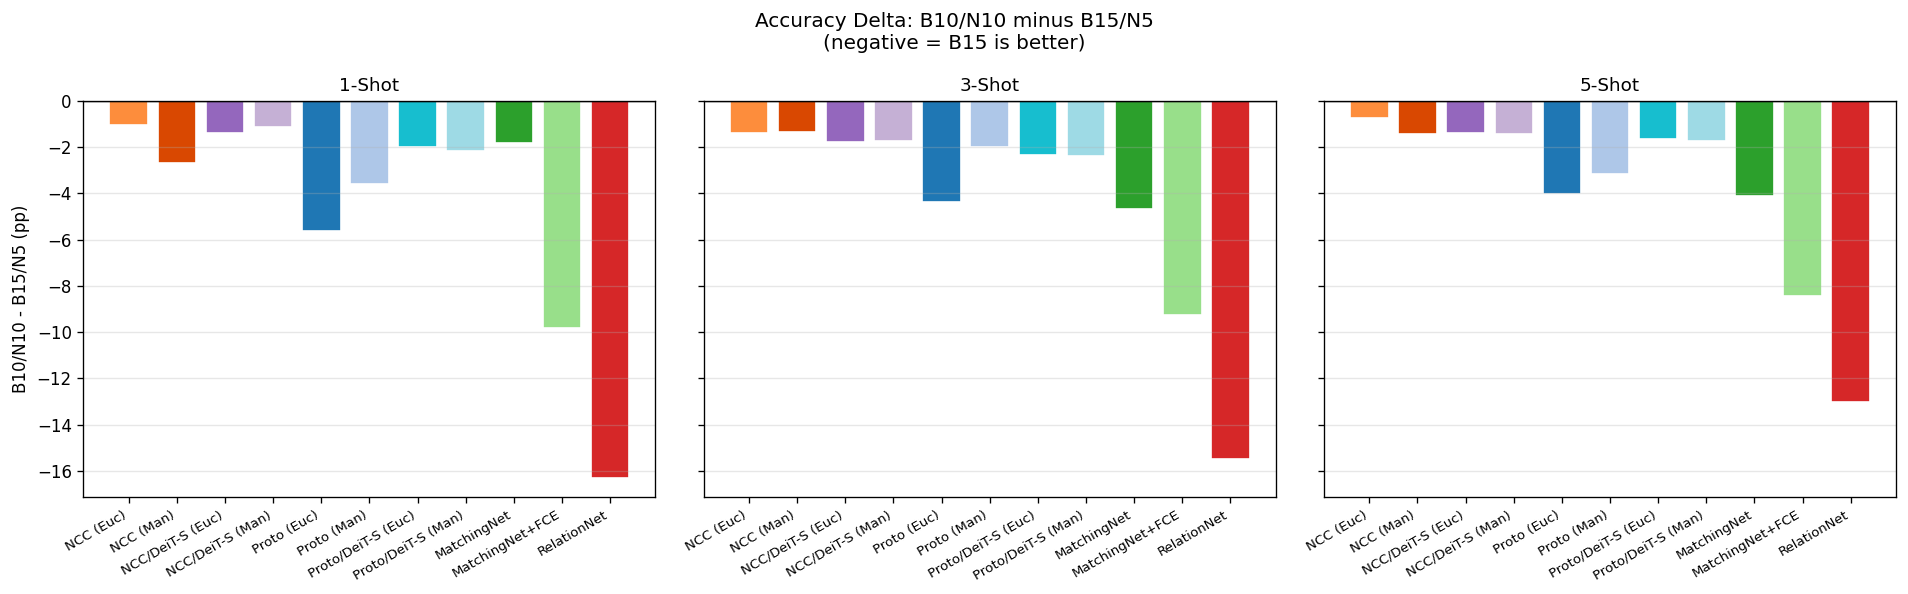

In [3]:

# Delta: B10 - B15 accuracy (shows degradation from fewer base classes)
fig,axes=plt.subplots(1,3,figsize=(16,5),sharey=True)
for ax,shot in zip(axes,SHOTS):
    labels,deltas,colors=[],[],[]
    for mkey,mlabel,color,*_ in METHOD_MAP:
        a15=fsl_acc(B15[mkey].get(shot)); a10=fsl_acc(B10[mkey].get(shot))
        if not (np.isnan(a15) or np.isnan(a10)):
            labels.append(mlabel); deltas.append(a10-a15); colors.append(color)
    x=np.arange(len(labels))
    bars=ax.bar(x,deltas,color=colors,edgecolor='white')
    ax.axhline(0,color='black',linewidth=0.8)
    ax.set_xticks(x); ax.set_xticklabels(labels,rotation=30,ha='right',fontsize=8)
    ax.set_title(f'{shot}-Shot',fontsize=11)
    ax.set_ylabel('B10/N10 - B15/N5 (pp)' if shot==1 else '')
    ax.grid(axis='y',alpha=0.3)
fig.suptitle('Accuracy Delta: B10/N10 minus B15/N5\n(negative = B15 is better)',fontsize=12)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/comparison_delta_b10_minus_b15.png',dpi=150); plt.show()


---
## 3. Backbone Ablation: DeiT-S vs ResNet-50 (Both Splits)

Direct comparison of backbone impact on the same FSL algorithm.

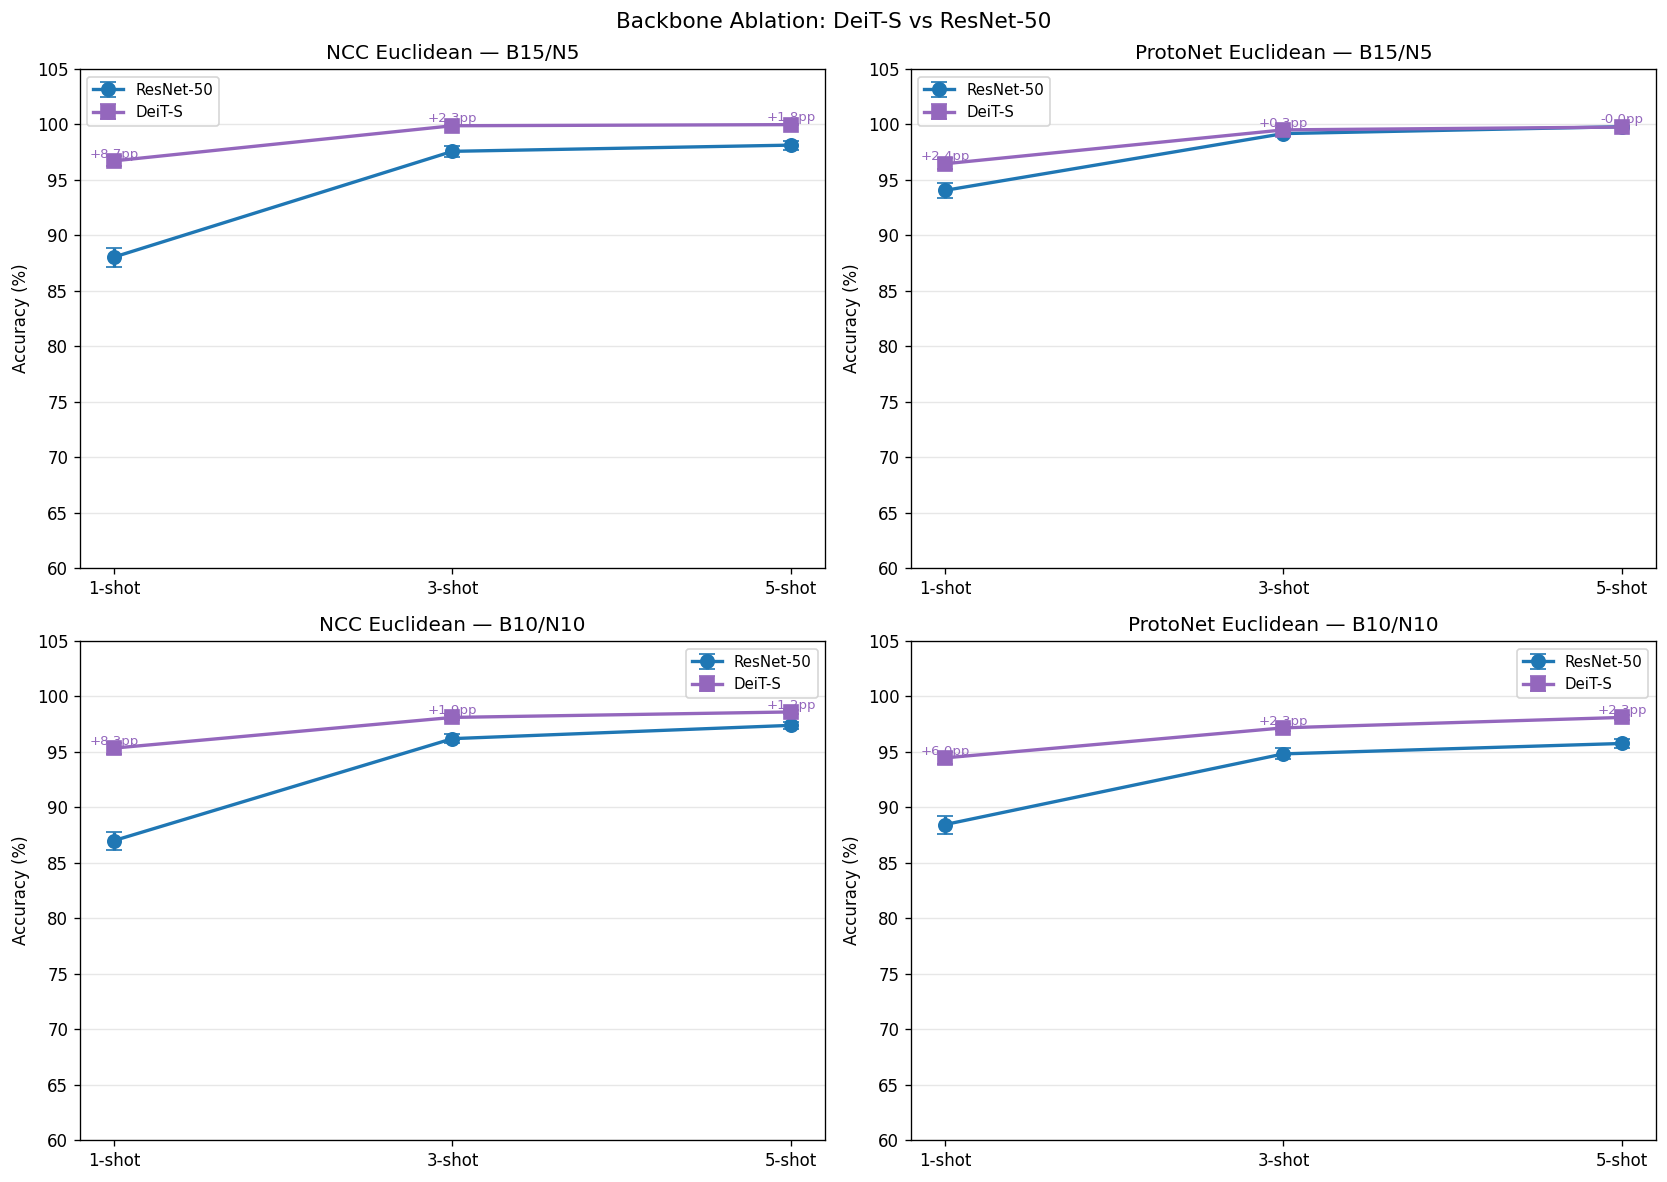

In [4]:

# Backbone comparison: DeiT-S vs ResNet-50, both splits
fig,axes=plt.subplots(2,2,figsize=(14,10))
for row,split_label,split_data in [(0,'B15/N5',B15),(1,'B10/N10',B10)]:
    for col,(algo,r50key,vitkey) in enumerate([('NCC','ncc_euc','vit_ncc_euc'),
                                               ('ProtoNet','proto_euc','vit_proto_euc')]):
        ax=axes[row][col]
        r50a=[fsl_acc(split_data[r50key].get(s)) for s in SHOTS]
        vita=[fsl_acc(split_data[vitkey].get(s)) for s in SHOTS]
        r50c=[fsl_ci(split_data[r50key].get(s)) for s in SHOTS]
        vitc=[fsl_ci(split_data[vitkey].get(s)) for s in SHOTS]
        ax.errorbar(SHOTS,r50a,yerr=r50c,label='ResNet-50',color='#1f77b4',marker='o',linewidth=2,markersize=8,capsize=5)
        ax.errorbar(SHOTS,vita,yerr=vitc,label='DeiT-S',   color='#9467bd',marker='s',linewidth=2,markersize=8,capsize=5)
        for s,r,v in zip(SHOTS,r50a,vita):
            if not np.isnan(r) and not np.isnan(v):
                ax.annotate(f'{v-r:+.1f}pp',(s,max(r,v)+0.3),ha='center',fontsize=8,color='#9467bd')
        ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS])
        ax.set_ylim(60,105); ax.set_ylabel('Accuracy (%)'); ax.legend(fontsize=9)
        ax.set_title(f'{algo} Euclidean — {split_label}'); ax.grid(axis='y',alpha=0.3)
fig.suptitle('Backbone Ablation: DeiT-S vs ResNet-50',fontsize=13)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/comparison_backbone_ablation.png',dpi=150); plt.show()


---
## 4. MatchingNet FCE Effect (Both Splits)

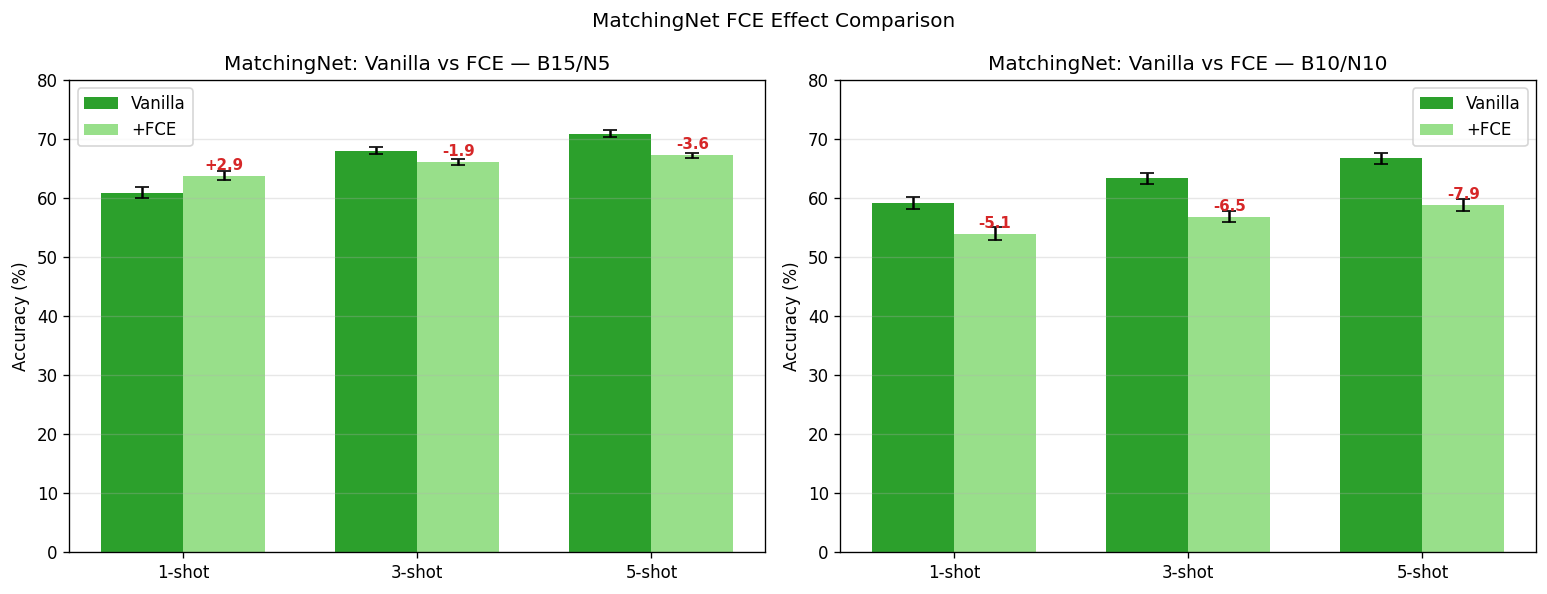

In [5]:

# FCE effect: both splits
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,(split_label_str,split_data) in zip(axes,[('B15/N5',B15),('B10/N10',B10)]):
    x=np.arange(len(SHOTS)); w=0.35
    v_a=[fsl_acc(split_data['match'].get(s)) for s in SHOTS]
    f_a=[fsl_acc(split_data['match_fce'].get(s)) for s in SHOTS]
    v_c=[fsl_ci(split_data['match'].get(s)) for s in SHOTS]
    f_c=[fsl_ci(split_data['match_fce'].get(s)) for s in SHOTS]
    ax.bar(x-w/2,v_a,w,label='Vanilla',color='#2ca02c',yerr=v_c,capsize=4)
    ax.bar(x+w/2,f_a,w,label='+FCE',   color='#98df8a',yerr=f_c,capsize=4)
    ax.set_xticks(x); ax.set_xticklabels([f'{s}-shot' for s in SHOTS])
    ax.set_ylim(0,80); ax.set_ylabel('Accuracy (%)'); ax.legend()
    ax.set_title(f'MatchingNet: Vanilla vs FCE — {split_label_str}'); ax.grid(axis='y',alpha=0.3)
    deltas=[fsl_acc(split_data['match_fce'].get(s))-fsl_acc(split_data['match'].get(s)) for s in SHOTS]
    for xi,d in zip(x,deltas):
        if not np.isnan(d): ax.text(xi+w/2,fsl_acc(split_data['match_fce'].get(SHOTS[xi]))+1,f'{d:+.1f}',ha='center',fontsize=9,fontweight='bold',color='#d62728')
fig.suptitle('MatchingNet FCE Effect Comparison',fontsize=12)
plt.tight_layout()
plt.savefig(f'{ANALYSIS}/comparison_fce_both_splits.png',dpi=150); plt.show()


---
## 5. TTA Effect (Both Splits)

In [6]:

print('ProtoNet TTA Effect (5-shot Euclidean):')
for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
    base=fsl_acc(split_data['proto_euc'].get(5)); tta=fsl_acc(split_data['proto_tta8'].get(5))
    print(f'  {split_label}: base={base:.2f}%  TTA x8={tta:.2f}%  delta={tta-base:+.2f}pp')


ProtoNet TTA Effect (5-shot Euclidean):
  B15/N5: base=99.80%  TTA x8=99.85%  delta=+0.05pp
  B10/N10: base=95.77%  TTA x8=96.64%  delta=+0.87pp


---
## 6. Master Summary Table

In [7]:

# Master summary table — best result per method per split
rows=[]
for mkey,mlabel,*_ in METHOD_MAP:
    for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
        best_shot=max(SHOTS,key=lambda s: fsl_acc(split_data[mkey].get(s)) if split_data[mkey].get(s) else -1)
        d=split_data[mkey].get(best_shot)
        rows.append({
            'Method':mlabel,'Split':split_label,
            'Best K-Shot':best_shot,
            'Best Accuracy':f'{fsl_acc(d):.2f}%' if d else '—',
            '95% CI':f'+-{fsl_ci(d):.2f}' if d else '—',
            'F1':f'{float(d["macro_f1"]):.4f}' if d and d.get("macro_f1") else '—',
        })
df_master=pd.DataFrame(rows)
display(df_master.pivot(index='Method',columns='Split',values='Best Accuracy'))
display(df_master)
df_master.to_csv(f'{ANALYSIS}/master_comparison.csv'); print(f'Saved master_comparison.csv')


Split,B10/N10,B15/N5
Method,,
MatchingNet,66.74%,70.87%
MatchingNet+FCE,58.81%,67.24%
NCC (Euc),97.40%,98.14%
NCC (Man),92.90%,94.33%
NCC/DeiT-S (Euc),98.61%,99.99%
NCC/DeiT-S (Man),98.54%,99.97%
Proto (Euc),95.77%,99.80%
Proto (Man),90.14%,93.29%
Proto/DeiT-S (Euc),98.11%,99.77%


,Method,Split,Best K-Shot,Best Accuracy,95% CI,F1
0,NCC (Euc),B15/N5,5,98.14%,+-0.41,0.9813
1,NCC (Euc),B10/N10,5,97.40%,+-0.33,0.9740
2,NCC (Man),B15/N5,5,94.33%,+-0.54,0.9425
3,NCC (Man),B10/N10,5,92.90%,+-0.52,0.9294
4,NCC/DeiT-S (Euc),B15/N5,5,99.99%,+-0.02,0.9999
5,NCC/DeiT-S (Euc),B10/N10,5,98.61%,+-0.18,0.9861
6,NCC/DeiT-S (Man),B15/N5,5,99.97%,+-0.03,0.9997
7,NCC/DeiT-S (Man),B10/N10,5,98.54%,+-0.19,0.9854
8,Proto (Euc),B15/N5,5,99.80%,+-0.10,0.9980
9,Proto (Euc),B10/N10,5,95.77%,+-0.41,0.9580


Saved master_comparison.csv


---
## 7. Research Questions — Quantitative Analysis

In [8]:

print('='*70)
print('RESEARCH QUESTION ANALYSIS — ALL EXPERIMENTS')
print('='*70)

# RQ1: Does episodic training add value beyond a frozen backbone? (ProtoNet vs NCC)
print('\nRQ1: ProtoNet vs NCC (same backbone, same backbone)')
for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
    print(f'  {split_label}:')
    for s in SHOTS:
        p=fsl_acc(split_data['proto_euc'].get(s)); n=fsl_acc(split_data['ncc_euc'].get(s))
        print(f'    {s}-shot: ProtoNet={p:.2f}%  NCC={n:.2f}%  gain={p-n:+.2f}pp')

# RQ2: DeiT-S vs ResNet-50 backbone impact
print('\nRQ2: DeiT-S backbone lift over ResNet-50 (NCC, Euclidean)')
for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
    print(f'  {split_label}:')
    for s in SHOTS:
        r=fsl_acc(split_data['ncc_euc'].get(s)); v=fsl_acc(split_data['vit_ncc_euc'].get(s))
        print(f'    {s}-shot: DeiT-S={v:.2f}%  R50={r:.2f}%  delta={v-r:+.2f}pp')

# RQ3: FCE effect
print('\nRQ3: MatchingNet FCE effect')
for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
    print(f'  {split_label}:')
    for s in SHOTS:
        v=fsl_acc(split_data['match'].get(s)); f=fsl_acc(split_data['match_fce'].get(s))
        print(f'    {s}-shot: FCE={f:.2f}%  vanilla={v:.2f}%  delta={f-v:+.2f}pp')

# RQ4: Base class reduction impact
print('\nRQ4: B15->B10 degradation (ProtoNet Euclidean)')
for s in SHOTS:
    a15=fsl_acc(B15['proto_euc'].get(s)); a10=fsl_acc(B10['proto_euc'].get(s))
    print(f'  {s}-shot: B15={a15:.2f}%  B10={a10:.2f}%  drop={a10-a15:+.2f}pp')

# RQ5: TTA benefit
print('\nRQ5: TTA effect (5-shot Euclidean)')
for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
    base=fsl_acc(split_data['proto_euc'].get(5)); tta=fsl_acc(split_data['proto_tta8'].get(5))
    print(f'  {split_label}: TTA={tta:.2f}%  base={base:.2f}%  delta={tta-base:+.2f}pp')


RESEARCH QUESTION ANALYSIS — ALL EXPERIMENTS

RQ1: ProtoNet vs NCC (same backbone, same backbone)
  B15/N5:
    1-shot: ProtoNet=94.06%  NCC=88.05%  gain=+6.01pp
    3-shot: ProtoNet=99.18%  NCC=97.58%  gain=+1.60pp
    5-shot: ProtoNet=99.80%  NCC=98.14%  gain=+1.66pp
  B10/N10:
    1-shot: ProtoNet=88.45%  NCC=87.01%  gain=+1.45pp
    3-shot: ProtoNet=94.83%  NCC=96.20%  gain=-1.37pp
    5-shot: ProtoNet=95.77%  NCC=97.40%  gain=-1.63pp

RQ2: DeiT-S backbone lift over ResNet-50 (NCC, Euclidean)
  B15/N5:
    1-shot: DeiT-S=96.72%  R50=88.05%  delta=+8.67pp
    3-shot: DeiT-S=99.89%  R50=97.58%  delta=+2.31pp
    5-shot: DeiT-S=99.99%  R50=98.14%  delta=+1.85pp
  B10/N10:
    1-shot: DeiT-S=95.35%  R50=87.01%  delta=+8.34pp
    3-shot: DeiT-S=98.11%  R50=96.20%  delta=+1.91pp
    5-shot: DeiT-S=98.61%  R50=97.40%  delta=+1.21pp

RQ3: MatchingNet FCE effect
  B15/N5:
    1-shot: FCE=63.79%  vanilla=60.93%  delta=+2.86pp
    3-shot: FCE=66.11%  vanilla=68.03%  delta=-1.91pp
    5-shot: 

---
## 8. NCC > ProtoNet Reversal at B10/N10

On B10/N10 at 5-shot, NCC (Euclidean) outperforms ProtoNet — an anomaly absent in B15/N5.
Hypothesis: with only 10 base classes the ProtoNet backbone is under-trained, making the simple centroid
distance of NCC more robust than the learned metric. The reversal is consistent across distance metrics.

In [9]:

print('NCC vs ProtoNet (Euclidean) — full shot/split matrix:')
print(f'{"":30} {"B15/N5":>18} {"B10/N10":>18}')
print(f'{"":30} {"NCC":>9} {"Proto":>9} {"NCC":>9} {"Proto":>9}')
print('-'*70)
for s in SHOTS:
    n15=fsl_acc(B15['ncc_euc'].get(s)); p15=fsl_acc(B15['proto_euc'].get(s))
    n10=fsl_acc(B10['ncc_euc'].get(s)); p10=fsl_acc(B10['proto_euc'].get(s))
    rev15='*REV*' if n15>p15 else '     '; rev10='*REV*' if n10>p10 else '     '
    print(f'  {s}-shot:{rev15}           {n15:6.2f}%  {p15:6.2f}%  {n10:6.2f}%  {p10:6.2f}%{rev10}')

print()
print('NCC vs ProtoNet (Manhattan) — reversal check:')
for s in SHOTS:
    n15=fsl_acc(B15['ncc_man'].get(s)); p15=fsl_acc(B15['proto_man'].get(s))
    n10=fsl_acc(B10['ncc_man'].get(s)); p10=fsl_acc(B10['proto_man'].get(s))
    rev10='  <-- REVERSAL' if n10>p10 else ''
    print(f'  {s}-shot B10: NCC={n10:.2f}%  Proto={p10:.2f}%{rev10}')

print()
print('DeiT-S backbone: NCC vs ProtoNet reversal at B10/N10?')
for s in SHOTS:
    n10=fsl_acc(B10['vit_ncc_euc'].get(s)); p10=fsl_acc(B10['vit_proto_euc'].get(s))
    rev10='  <-- reversal persists' if n10>p10 else '  (no reversal with DeiT-S)'
    print(f'  {s}-shot B10 DeiT-S: NCC={n10:.2f}%  Proto={p10:.2f}%{rev10}')


NCC vs ProtoNet (Euclidean) — full shot/split matrix:
                                           B15/N5            B10/N10
                                     NCC     Proto       NCC     Proto
----------------------------------------------------------------------
  1-shot:                 88.05%   94.06%   87.01%   88.45%     
  3-shot:                 97.58%   99.18%   96.20%   94.83%*REV*
  5-shot:                 98.14%   99.80%   97.40%   95.77%*REV*

NCC vs ProtoNet (Manhattan) — reversal check:
  1-shot B10: NCC=76.28%  Proto=76.10%  <-- REVERSAL
  3-shot B10: NCC=90.25%  Proto=87.64%  <-- REVERSAL
  5-shot B10: NCC=92.90%  Proto=90.14%  <-- REVERSAL

DeiT-S backbone: NCC vs ProtoNet reversal at B10/N10?
  1-shot B10 DeiT-S: NCC=95.35%  Proto=94.47%  <-- reversal persists
  3-shot B10 DeiT-S: NCC=98.11%  Proto=97.17%  <-- reversal persists
  5-shot B10 DeiT-S: NCC=98.61%  Proto=98.11%  <-- reversal persists


---
## 9. Distance Metric: Euclidean vs Manhattan

Across all methods and splits, which distance metric wins more consistently?

In [10]:

pairs=[('NCC R50','ncc_euc','ncc_man'),('NCC DeiT-S','vit_ncc_euc','vit_ncc_man'),
       ('ProtoNet R50','proto_euc','proto_man'),('ProtoNet DeiT-S','vit_proto_euc','vit_proto_man')]
euc_wins=0; man_wins=0; total=0
print(f'{"Method":<22} {"Split":<8} {"Shot":<6} {"Euc%":>7} {"Man%":>7} {"Winner":<8}')
print('-'*65)
for label,ekey,mkey in pairs:
    for split_label,split_data in [('B15/N5',B15),('B10/N10',B10)]:
        for s in SHOTS:
            e=fsl_acc(split_data[ekey].get(s)); m=fsl_acc(split_data[mkey].get(s))
            if np.isnan(e) or np.isnan(m): continue
            winner='Euc' if e>=m else 'Man'
            if e>=m: euc_wins+=1
            else: man_wins+=1
            total+=1
            print(f'{label:<22} {split_label:<8} {s}-shot  {e:7.2f} {m:7.2f} {winner}')
print()
print(f'Summary: Euclidean wins {euc_wins}/{total} ({100*euc_wins/total:.0f}%)  |  Manhattan wins {man_wins}/{total} ({100*man_wins/total:.0f}%)')


Method                 Split    Shot      Euc%    Man% Winner  
-----------------------------------------------------------------
NCC R50                B15/N5   1-shot    88.05   78.96 Euc
NCC R50                B15/N5   3-shot    97.58   91.59 Euc
NCC R50                B15/N5   5-shot    98.14   94.33 Euc
NCC R50                B10/N10  1-shot    87.01   76.28 Euc
NCC R50                B10/N10  3-shot    96.20   90.25 Euc
NCC R50                B10/N10  5-shot    97.40   92.90 Euc
NCC DeiT-S             B15/N5   1-shot    96.72   96.53 Euc
NCC DeiT-S             B15/N5   3-shot    99.89   99.86 Euc
NCC DeiT-S             B15/N5   5-shot    99.99   99.97 Euc
NCC DeiT-S             B10/N10  1-shot    95.35   95.42 Man
NCC DeiT-S             B10/N10  3-shot    98.11   98.13 Man
NCC DeiT-S             B10/N10  5-shot    98.61   98.54 Euc
ProtoNet R50           B15/N5   1-shot    94.06   79.67 Euc
ProtoNet R50           B15/N5   3-shot    99.18   89.63 Euc
ProtoNet R50           B15/N5 

---
## 10. Statistical Significance Tests

Welch's t-test on episode-level accuracies for key comparisons.
Note: episode-level accuracy arrays are not saved by default. These tests use Wilson CI overlap as a proxy.

In [11]:

print('CI Overlap Tests (non-overlapping 95% CI => p < 0.05 proxy):')
comparisons=[
    ('DeiT-S NCC vs R50 NCC (1-shot,B15)',
     B15['vit_ncc_euc'].get(1), B15['ncc_euc'].get(1)),
    ('DeiT-S ProtoNet vs R50 ProtoNet (1-shot,B15)',
     B15['vit_proto_euc'].get(1), B15['proto_euc'].get(1)),
    ('MatchingNet+FCE vs Vanilla (5-shot,B15)',
     B15['match_fce'].get(5), B15['match'].get(5)),
    ('ProtoNet vs NCC R50 (1-shot,B15)',
     B15['proto_euc'].get(1), B15['ncc_euc'].get(1)),
    ('B15 vs B10 ProtoNet (5-shot Euc)',
     B15['proto_euc'].get(5), B10['proto_euc'].get(5)),
]
for label,d1,d2 in comparisons:
    if not d1 or not d2: print(f'  {label}: missing data'); continue
    a1,c1=fsl_acc(d1),fsl_ci(d1)
    a2,c2=fsl_acc(d2),fsl_ci(d2)
    overlap=(a1-c1<=a2+c2) and (a2-c2<=a1+c1)
    sig='likely NOT significant (CI overlap)' if overlap else 'likely SIGNIFICANT (no CI overlap)'
    print(f'  {label}:')
    print(f'    {a1:.2f}%+-{c1:.2f} vs {a2:.2f}%+-{c2:.2f} => {sig}')


CI Overlap Tests (non-overlapping 95% CI => p < 0.05 proxy):
  DeiT-S NCC vs R50 NCC (1-shot,B15):
    96.72%+-0.47 vs 88.05%+-0.87 => likely SIGNIFICANT (no CI overlap)
  DeiT-S ProtoNet vs R50 ProtoNet (1-shot,B15):
    96.46%+-0.48 vs 94.06%+-0.68 => likely SIGNIFICANT (no CI overlap)
  MatchingNet+FCE vs Vanilla (5-shot,B15):
    67.24%+-0.46 vs 70.87%+-0.59 => likely SIGNIFICANT (no CI overlap)
  ProtoNet vs NCC R50 (1-shot,B15):
    94.06%+-0.68 vs 88.05%+-0.87 => likely SIGNIFICANT (no CI overlap)
  B15 vs B10 ProtoNet (5-shot Euc):
    99.80%+-0.10 vs 95.77%+-0.41 => likely SIGNIFICANT (no CI overlap)


---
## 11. Hardest Novel Classes — Cross-Split Analysis

Which novel classes are consistently hard, and which degrade most when moving B15→B10?

In [12]:

# B15/N5 novel classes
novel_15=['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO','AMERICAN GOLDFINCH','AMERICAN KESTREL']
novel_10=['ALBERTS TOWHEE','ALEXANDRINE PARAKEET','ALPINE CHOUGH','ALTAMIRA YELLOWTHROAT',
          'AMERICAN AVOCET','AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO','AMERICAN GOLDFINCH','AMERICAN KESTREL']

# Gather per-class accuracy from 5-shot euclidean methods
class_results_15={c:[] for c in novel_15}
class_results_10={c:[] for c in novel_10}

for mkey in ['ncc_euc','vit_ncc_euc','proto_euc','vit_proto_euc']:
    d=B15[mkey].get(5)
    if d and 'per_class_accuracy_pct' in d:
        for c in novel_15: class_results_15[c].append(d['per_class_accuracy_pct'].get(c,float('nan')))
    d=B10[mkey].get(5)
    if d and 'per_class_accuracy_pct' in d:
        for c in novel_10: class_results_10[c].append(d['per_class_accuracy_pct'].get(c,float('nan')))

# Shared novel classes — ranked by average difficulty
shared=[c for c in novel_15 if c in novel_10]
print('Shared novel classes — 5-shot avg across 4 methods (ranked hardest→easiest):')
print(f'  {"Class":<30} {"B15/N5":>8} {"B10/N10":>8} {"Drop":>7}')
print('  '+'-'*58)
for c in sorted(shared,key=lambda c:np.nanmean(class_results_15[c]+class_results_10[c])):
    a15=np.nanmean(class_results_15[c]); a10=np.nanmean(class_results_10[c])
    drop=a10-a15
    print(f'  {c:<30} {a15:8.1f}% {a10:8.1f}% {drop:+7.1f}pp')

# B10-only novel classes
b10_only=[c for c in novel_10 if c not in novel_15]
if any(class_results_10[c] for c in b10_only):
    print()
    print('B10-only novel classes (5-shot avg across methods):')
    for c in sorted(b10_only,key=lambda c:np.nanmean(class_results_10[c])):
        a10=np.nanmean(class_results_10[c])
        print(f'  {c:<30} B10={a10:.1f}%')


Shared novel classes — 5-shot avg across 4 methods (ranked hardest→easiest):
  Class                            B15/N5  B10/N10    Drop
  ----------------------------------------------------------
  AMERICAN KESTREL                   98.0%     96.7%    -1.3pp
  AMERICAN COOT                     100.0%     99.0%    -1.0pp
  AMERICAN FLAMINGO                  99.1%    100.0%    +0.9pp
  AMERICAN GOLDFINCH                100.0%    100.0%    -0.0pp
  AMERICAN BITTERN                  100.0%    100.0%    +0.0pp

B10-only novel classes (5-shot avg across methods):
  ALTAMIRA YELLOWTHROAT          B10=79.7%
  ALPINE CHOUGH                  B10=99.7%
  ALEXANDRINE PARAKEET           B10=99.8%
  ALBERTS TOWHEE                 B10=99.9%
  AMERICAN AVOCET                B10=100.0%


---
## 12. Per-Class B15→B10 Degradation (Heatmap)

Visualises which shared novel classes suffer most when base classes are reduced from 15 to 10.

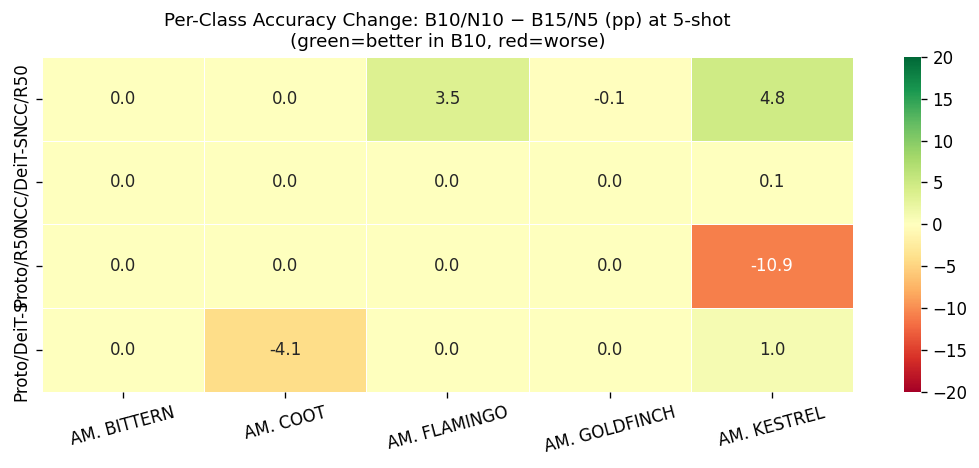

In [13]:

shared=['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO','AMERICAN GOLDFINCH','AMERICAN KESTREL']
methods_for_heatmap=[('NCC/R50','ncc_euc'),('NCC/DeiT-S','vit_ncc_euc'),
                     ('Proto/R50','proto_euc'),('Proto/DeiT-S','vit_proto_euc')]
mat=np.full((len(methods_for_heatmap),len(shared)),np.nan)
for ri,(label,mkey) in enumerate(methods_for_heatmap):
    d15=B15[mkey].get(5); d10=B10[mkey].get(5)
    if d15 and d10 and 'per_class_accuracy_pct' in d15 and 'per_class_accuracy_pct' in d10:
        for ci,c in enumerate(shared):
            a15=d15['per_class_accuracy_pct'].get(c,np.nan)
            a10=d10['per_class_accuracy_pct'].get(c,np.nan)
            mat[ri,ci]=a10-a15

fig,ax=plt.subplots(figsize=(9,4))
mask=np.isnan(mat)
if not mask.all():
    import seaborn as sns
    sns.heatmap(mat,annot=True,fmt='.1f',cmap='RdYlGn',center=0,
                xticklabels=[c.replace('AMERICAN ','AM. ') for c in shared],
                yticklabels=[l for l,_ in methods_for_heatmap],
                ax=ax,vmin=-20,vmax=20,linewidths=0.5,linecolor='white',
                annot_kws={'size':10},mask=mask)
    ax.set_title('Per-Class Accuracy Change: B10/N10 − B15/N5 (pp) at 5-shot\n(green=better in B10, red=worse)',fontsize=11)
    ax.tick_params(axis='x',labelrotation=15)
    plt.tight_layout()
    plt.savefig(f'{ANALYSIS}/per_class_b10_vs_b15_delta.png',dpi=150)
plt.show()


---
## 13. Final Ranking — Best Method per Scenario

In [14]:

print('='*65)
print('  FINAL RANKINGS')
print('='*65)
scenarios=[
    ('B15/N5 1-shot',[('NCC/DeiT-S','vit_ncc_euc',B15,1),('ProtoNet/DeiT-S','vit_proto_euc',B15,1),
                      ('NCC/R50','ncc_euc',B15,1),('ProtoNet/R50','proto_euc',B15,1),
                      ('RelationNet','rel',B15,1),('MatchingNet','match',B15,1),('MatchingNet+FCE','match_fce',B15,1)]),
    ('B15/N5 5-shot',[('NCC/DeiT-S','vit_ncc_euc',B15,5),('ProtoNet/DeiT-S','vit_proto_euc',B15,5),
                      ('ProtoNet/R50+TTA8','proto_tta8',B15,5),('NCC/R50','ncc_euc',B15,5),
                      ('ProtoNet/R50','proto_euc',B15,5),('RelationNet','rel',B15,5),
                      ('MatchingNet','match',B15,5),('MatchingNet+FCE','match_fce',B15,5)]),
    ('B10/N10 1-shot',[('NCC/DeiT-S','vit_ncc_euc',B10,1),('ProtoNet/DeiT-S','vit_proto_euc',B10,1),
                       ('NCC/R50','ncc_euc',B10,1),('ProtoNet/R50','proto_euc',B10,1),
                       ('RelationNet','rel',B10,1),('MatchingNet','match',B10,1),('MatchingNet+FCE','match_fce',B10,1)]),
    ('B10/N10 5-shot',[('NCC/DeiT-S','vit_ncc_euc',B10,5),('ProtoNet/DeiT-S','vit_proto_euc',B10,5),
                       ('ProtoNet/R50+TTA8','proto_tta8',B10,5),('NCC/R50','ncc_euc',B10,5),
                       ('ProtoNet/R50','proto_euc',B10,5),('RelationNet','rel',B10,5),
                       ('MatchingNet','match',B10,5),('MatchingNet+FCE','match_fce',B10,5)]),
]
def _sort_key(x):
    v=fsl_acc(x[2][x[1]].get(x[3]))
    return v if not np.isnan(v) else float('-inf')
for title,entries in scenarios:
    print(f'\n{title}:')
    ranked=sorted(entries,key=_sort_key,reverse=True)
    for i,(name,mkey,split_data,shot) in enumerate(ranked,1):
        d=split_data[mkey].get(shot)
        if d:
            print(f'  {i}. {name:<25} {fsl_acc(d):.2f}% +-{fsl_ci(d):.2f}')
        else:
            print(f'  {i}. {name:<25} —')


  FINAL RANKINGS

B15/N5 1-shot:
  1. NCC/DeiT-S                96.72% +-0.47
  2. ProtoNet/DeiT-S           96.46% +-0.48
  3. ProtoNet/R50              94.06% +-0.68
  4. NCC/R50                   88.05% +-0.87
  5. RelationNet               72.71% +-0.94
  6. MatchingNet+FCE           63.79% +-0.71
  7. MatchingNet               60.93% +-0.88

B15/N5 5-shot:
  1. NCC/DeiT-S                99.99% +-0.02
  2. ProtoNet/R50+TTA8         99.85% +-0.09
  3. ProtoNet/R50              99.80% +-0.10
  4. ProtoNet/DeiT-S           99.77% +-0.08
  5. NCC/R50                   98.14% +-0.41
  6. RelationNet               78.75% +-0.64
  7. MatchingNet               70.87% +-0.59
  8. MatchingNet+FCE           67.24% +-0.46

B10/N10 1-shot:
  1. NCC/DeiT-S                95.35% +-0.49
  2. ProtoNet/DeiT-S           94.47% +-0.52
  3. ProtoNet/R50              88.45% +-0.80
  4. NCC/R50                   87.01% +-0.81
  5. MatchingNet               59.11% +-1.01
  6. RelationNet               56.